# Antimalarial SVM Model — SVM-1 (Avalon + 5 Descriptors)
## Based on: *Kore et al., BMC Chemistry, 2025* — https://doi.org/10.1186/s13065-025-01395-4

**Feature matrix:** Avalon MFP (1024 bits) **concatenated** with 5 physicochemical descriptors:
| # | Descriptor | Source |
|---|-----------|--------|
| 1 | **MW** — Molecular Weight | OpenChemLib |
| 2 | **TPSA** — Topological Polar Surface Area | OpenChemLib |
| 3 | **cLogP** — Calculated partition coefficient | OpenChemLib |
| 4 | **AromaticRings** — Number of aromatic rings | OpenChemLib |
| 5 | **BaN** — Basic Nitrogen count | OpenChemLib (pKa-based port of AtomFunctionAnalyzer) |

**Model:** Support Vector Machine (`sklearn.svm.SVC`)  
**Kernels tested:** RBF (Radial Basis Function), Linear, Polynomial  
**Input:** Pre-split CSV files (train / validation / test) — no ChEMBL fetch or re-splitting needed.

> **Descriptor backend:** OpenChemLib-JS (via Node.js subprocess). All 5 descriptors are calculated
> using `openchemlib` npm package — no DataWarrior required.
>
> **Note:** SVM is sensitive to feature scaling — the StandardScaler fitted on the training set
> is essential for good performance.

## 0. Install Dependencies

In [14]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/antimalarial_project/'

import os
os.makedirs(PROJECT_DIR, exist_ok=True)

import matplotlib.pyplot as plt

def save_fig(filename, dpi=150):
    path = PROJECT_DIR + filename
    plt.savefig(path, dpi=dpi, bbox_inches='tight')
    print(f"Saved to Drive: {path}")

print(f"PROJECT_DIR: {PROJECT_DIR}")
print("Drive mounted and ready.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR: /content/drive/MyDrive/antimalarial_project/
Drive mounted and ready.


In [15]:
import subprocess, sys

# Core packages (scikit-learn already includes SVM)
for pkg in ["rdkit", "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "tqdm"]:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

# OpenChemLib-JS via npm
subprocess.run(['npm', 'install', 'openchemlib', '--prefix', '/tmp/ocl'],
               check=True, capture_output=True)
print("All packages installed (including openchemlib-JS).")
print("Note: SVM is included in scikit-learn — no extra install needed.")

All packages installed (including openchemlib-JS).
Note: SVM is included in scikit-learn — no extra install needed.


## 1. Imports

In [16]:
import warnings
warnings.filterwarnings('ignore')

import subprocess, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from tqdm.notebook import tqdm
import pickle, os

# RDKit — for Avalon fingerprints and SMILES validation
from rdkit import Chem, DataStructs

# Avalon
try:
    from rdkit.Avalon import pyAvalonTools
    AVALON_AVAILABLE = True
    print("Avalon fingerprints available")
except ImportError:
    AVALON_AVAILABLE = False
    print("WARNING: Avalon not available. Falling back to RDKit topological FP.")

# SVM and scikit-learn utilities
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, matthews_corrcoef,
    cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from scipy.spatial.distance import cdist

import sklearn
print(f"scikit-learn version: {sklearn.__version__}")
print("All imports successful")

Avalon fingerprints available
scikit-learn version: 1.6.1
All imports successful


## 2. Configuration

In [17]:
# ============================================================
#  EDIT THESE to match your files
# ============================================================

TRAIN_CSV  = "/content/train .csv"        # 60% — used for SVM training
VAL_CSV    = "/content/validation .csv"   # 20% — used for hyperparameter optimisation
TEST_CSV   = "/content/test .csv"         # 20% — held-out external test set

SMILES_COL = "Molecule (RDKit Mol) (Canonical)"  # Column with SMILES strings
LABEL_COL  = "Category"                           # Activity: Active / Inactive

AVALON_NBITS = 1024   # Paper used 1024
DESC_NAMES   = ['MW', 'TPSA', 'cLogP', 'AromaticRings', 'BaN']

# Label mapping (string → int)
LABEL_MAP = {'Active': 1, 'Inactive': 0}

print(f"Train CSV  : {TRAIN_CSV}")
print(f"Val CSV    : {VAL_CSV}")
print(f"Test CSV   : {TEST_CSV}")
print(f"SMILES col : {SMILES_COL}")
print(f"Label col  : {LABEL_COL}")
print(f"Avalon bits: {AVALON_NBITS}")
print(f"Descriptor backend: OpenChemLib-JS (Node.js)")

Train CSV  : /content/train .csv
Val CSV    : /content/validation .csv
Test CSV   : /content/test .csv
SMILES col : Molecule (RDKit Mol) (Canonical)
Label col  : Category
Avalon bits: 1024
Descriptor backend: OpenChemLib-JS (Node.js)


## 3. Load Pre-Split CSV Files

In [18]:
def load_csv(path, label):
    df = pd.read_csv(path)
    print(f"{label:20s}: {len(df):,} rows  |  columns: {list(df.columns)}")
    return df

train_df = load_csv(TRAIN_CSV, "Training set")
val_df   = load_csv(VAL_CSV,   "Validation set")
test_df  = load_csv(TEST_CSV,  "External test set")

# Validate required columns
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    for col in [SMILES_COL, LABEL_COL]:
        assert col in df.columns, f"Column '{col}' not found in {name} CSV!"

# Class distribution
print("\nClass distribution:")
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    vc = df[LABEL_COL].value_counts()
    print(f"  {name:8s}: Active={vc.get('Active', 0):,}  Inactive={vc.get('Inactive', 0):,}  Total={len(df):,}")

Training set        : 9,070 rows  |  columns: ['Category', 'Molecule (RDKit Mol) (Canonical)']
Validation set      : 3,024 rows  |  columns: ['Category', 'Molecule (RDKit Mol) (Canonical)']
External test set   : 3,024 rows  |  columns: ['Category', 'Molecule (RDKit Mol) (Canonical)']

Class distribution:
  Train   : Active=4,223  Inactive=4,847  Total=9,070
  Val     : Active=1,408  Inactive=1,616  Total=3,024
  Test    : Active=1,408  Inactive=1,616  Total=3,024


In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 4. Descriptor Calculation

### Feature Vector = Avalon FP (1024 bits) + 5 Descriptors = 1029 features

Same descriptor pipeline as RF and XGBoost notebooks.

> **Important for SVM:** Unlike tree-based models, SVMs are highly sensitive to feature scale.
> The StandardScaler is critical here — without it, large-valued features (like MW ~300-500)
> would dominate the binary Avalon bits (0 or 1), completely distorting the model.

In [20]:
import subprocess, json
import numpy as np

_OCL_LIB = '/tmp/ocl/node_modules/openchemlib/dist/openchemlib.js'

_OCL_JS_SCRIPT = f"""
import OCL from '{_OCL_LIB}';
const {{ Molecule, MoleculeProperties }} = OCL;

function getFakeOxoCount(mol, atom) {{
  let n = 0;
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {{
    const no = mol.getAtomicNo(mol.getConnAtom(atom, i));
    if (mol.getConnBondOrder(atom, i) === 2 && (no===7||no===8||no===16)) n++;
  }}
  return n;
}}

function isStabilized(mol, atom, twice) {{
  let found = false;
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {{
    const bond = mol.getConnBond(atom, i);
    if (!mol.isAromaticBond(bond) && mol.getConnBondOrder(atom, i) === 1) {{
      const conn = mol.getConnAtom(atom, i);
      if (!mol.isAromaticAtom(conn) &&
          ((mol.getAtomicNo(conn)===6 && getFakeOxoCount(mol,conn)===1) ||
           (mol.getAtomicNo(conn)===16 && getFakeOxoCount(mol,conn)===2))) {{
        if (found || !twice) return true;
        found = true;
      }}
    }}
  }}
  return false;
}}

function isVinylogFakeOxo(mol, atom) {{
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {{
    if (mol.getConnBondOrder(atom, i) !== 1) {{
      const conn = mol.getConnAtom(atom, i);
      for (let j = 0; j < mol.getConnAtoms(conn); j++)
        if (mol.getConnBondOrder(conn,j)===1 && getFakeOxoCount(mol,mol.getConnAtom(conn,j))!==0)
          return true;
    }}
  }}
  return false;
}}

function isBasicNitrogen(mol, atom) {{
  if (mol.getAtomicNo(atom) !== 7) return false;
  if (mol.getAtomCharge(atom) !== 0) return false;
  if (mol.getConnAtoms(atom) + mol.getAtomPi(atom) > 3) return false;
  if (mol.isAromaticAtom(atom)) {{
    if (mol.getAtomPi(atom) !== 1) return false;
    let donorCount = 0;
    for (let i = 0; i < mol.getConnAtoms(atom); i++) {{
      const conn = mol.getConnAtom(atom, i);
      if (!mol.isAromaticAtom(conn)) continue;
      for (let j = 0; j < mol.getConnAtoms(conn); j++) {{
        const c2 = mol.getConnAtom(conn, j);
        if (c2 === atom) continue;
        const no = mol.getAtomicNo(c2);
        if ((no===7||no===8) && mol.getConnAtoms(c2)<3) donorCount++;
      }}
    }}
    return donorCount >= 1;
  }} else {{
    if (mol.getAtomPi(atom) !== 0) return false;
    if (getFakeOxoCount(mol, atom) !== 0) return false;
    if (isStabilized(mol, atom, false)) return false;
    if (isVinylogFakeOxo(mol, atom)) return false;
    return true;
  }}
}}

function basicNitrogenCount(mol) {{
  let count = 0;
  for (let i = 0; i < mol.getAllAtoms(); i++) {{
    if (isBasicNitrogen(mol, i)) count++;
  }}
  return count;
}}

const smilesList = JSON.parse(process.argv[2]);
const results = {{}};

for (const smi of smilesList) {{
  try {{
    const mol = OCL.Molecule.fromSmiles(smi);
    mol.ensureHelperArrays(OCL.Molecule.cHelperRings | OCL.Molecule.cHelperAromaticity | OCL.Molecule.cHelperParities);
    const props = new MoleculeProperties(mol);
    const formula = mol.getMolecularFormula();
    results[smi] = [
      formula.relativeWeight,
      props.polarSurfaceArea,
      props.logP,
      mol.getAromaticRingCount(),
      basicNitrogenCount(mol)
    ];
  }} catch(e) {{
    results[smi] = null;
  }}
}}

process.stdout.write(JSON.stringify(results));
"""

def run_ocl_descriptors(smiles_list):
    """Run OpenChemLib-JS descriptor calculation via Node.js subprocess."""
    script_path = '/tmp/ocl_desc.mjs'
    with open(script_path, 'w') as f:
        f.write(_OCL_JS_SCRIPT)

    BATCH_SIZE = 500
    all_results = {}
    for i in range(0, len(smiles_list), BATCH_SIZE):
        batch = smiles_list[i:i+BATCH_SIZE]
        result = subprocess.run(
            ['node', script_path, json.dumps(batch)], # Removed --input-type=module
            capture_output=True, text=True, timeout=120
        )
        if result.returncode != 0:
            print(f"OCL error batch {i}: {result.stderr[:200]}")
            continue
        batch_res = json.loads(result.stdout)
        for smi, vals in batch_res.items():
            if vals is not None:
                all_results[smi] = np.array(vals, dtype=np.float32)
    return all_results


def calc_avalon_fp(mol, n_bits=1024):
    if AVALON_AVAILABLE:
        bv = pyAvalonTools.GetAvalonFP(mol, nBits=n_bits)
    else:
        from rdkit.Chem import RDKFingerprint
        bv = RDKFingerprint(mol, fpSize=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(bv, arr)
    return arr


print("OCL descriptor functions defined.")

OCL descriptor functions defined.


In [21]:
def build_feature_matrix(df, smiles_col, label_col,
                          n_bits=1024, scaler=None, fit_scaler=False, set_name="Set"):
    """
    Build X = [Avalon FP | standardised 5 descriptors], y = labels.
    Returns: X, y, valid_df, fp_matrix, [scaler if fit_scaler else None]

    NOTE for SVM: scaling is MORE critical here than for tree-based models.
    The SVM finds a hyperplane in feature space — if features have very
    different ranges, the hyperplane will be dominated by the large-scale ones.
    """
    print(f"\nBuilding features for {set_name} ({len(df):,} molecules)...")

    # Step 1: validate SMILES
    valid_idx, valid_smiles = [], []
    for original_idx, row in df.iterrows():
        mol = Chem.MolFromSmiles(str(row[smiles_col]))
        if mol is not None:
            valid_idx.append(original_idx)
            valid_smiles.append(str(row[smiles_col]))

    valid_df = df.loc[valid_idx].reset_index(drop=True)
    print(f"  Dropped: {len(df) - len(valid_idx)} invalid SMILES")

    # Step 2: batch descriptor calculation
    print(f"  [OCL] Calculating descriptors for {len(valid_smiles)} molecules...")
    desc_map = run_ocl_descriptors(valid_smiles)

    # Step 3: build matrices
    fp_list, desc_list, keep_idx = [], [], []
    for i, (smi, orig_idx) in enumerate(zip(valid_smiles, valid_idx)):
        if smi not in desc_map:
            continue
        mol = Chem.MolFromSmiles(smi)
        try:
            fp = calc_avalon_fp(mol, n_bits=n_bits)
        except Exception as e:
            print(f"  FP error for {smi}: {e}")
            continue
        fp_list.append(fp)
        desc_list.append(desc_map[smi])
        keep_idx.append(i)

    valid_df = valid_df.iloc[keep_idx].reset_index(drop=True)
    fp_mat   = np.array(fp_list, dtype=np.float32)
    desc_mat = np.array(desc_list, dtype=np.float32)

    # Step 4: standardise descriptors (critical for SVM)
    if fit_scaler:
        scaler = StandardScaler()
        desc_scaled = scaler.fit_transform(desc_mat)
        print(f"  Scaler fitted on {set_name}")
    else:
        desc_scaled = scaler.transform(desc_mat)

    X = np.hstack([fp_mat, desc_scaled]).astype(np.float32)
    y = valid_df[label_col].map(LABEL_MAP).values.astype(np.int32)

    print(f"  Final shape: X={X.shape}, y={y.shape}")
    print(f"  Class balance: Active={y.sum()}, Inactive={(y==0).sum()}")

    if fit_scaler:
        return X, y, valid_df, fp_mat, scaler
    return X, y, valid_df, fp_mat, None


# Build train features and fit scaler
X_train, y_train, train_valid_df, X_train_fp, scaler = build_feature_matrix(
    train_df, SMILES_COL, LABEL_COL,
    n_bits=AVALON_NBITS, fit_scaler=True, set_name="Training"
)

# Build val features
X_val, y_val, val_valid_df, X_val_fp, _ = build_feature_matrix(
    val_df, SMILES_COL, LABEL_COL,
    n_bits=AVALON_NBITS, scaler=scaler, fit_scaler=False, set_name="Validation"
)

# Build test features
X_test, y_test, test_valid_df, X_test_fp, _ = build_feature_matrix(
    test_df, SMILES_COL, LABEL_COL,
    n_bits=AVALON_NBITS, scaler=scaler, fit_scaler=False, set_name="Test"
)

# Dev set = train + val (used for final model and CV)
X_dev    = np.vstack([X_train, X_val])
y_dev    = np.concatenate([y_train, y_val])
X_dev_fp = np.vstack([X_train_fp, X_val_fp])
print(f"\nDev set: {X_dev.shape[0]:,} samples (train + val)")


Building features for Training (9,070 molecules)...
  Dropped: 0 invalid SMILES
  [OCL] Calculating descriptors for 9070 molecules...
  Scaler fitted on Training
  Final shape: X=(9070, 1029), y=(9070,)
  Class balance: Active=4223, Inactive=4847

Building features for Validation (3,024 molecules)...
  Dropped: 0 invalid SMILES
  [OCL] Calculating descriptors for 3024 molecules...
  Final shape: X=(3024, 1029), y=(3024,)
  Class balance: Active=1408, Inactive=1616

Building features for Test (3,024 molecules)...
  Dropped: 0 invalid SMILES
  [OCL] Calculating descriptors for 3024 molecules...
  Final shape: X=(3024, 1029), y=(3024,)
  Class balance: Active=1408, Inactive=1616

Dev set: 12,094 samples (train + val)


## 5. Evaluation Metrics

In [22]:
def compute_metrics(y_true, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    m = {
        'Accuracy':    accuracy_score(y_true, y_pred),
        'Precision':   precision_score(y_true, y_pred, zero_division=0),
        'Sensitivity': recall_score(y_true, y_pred, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        'F1':          f1_score(y_true, y_pred, zero_division=0),
        'Kappa':       cohen_kappa_score(y_true, y_pred),
        'MCC':         matthews_corrcoef(y_true, y_pred),
    }
    if y_prob is not None:
        m['AUROC'] = roc_auc_score(y_true, y_prob)
    m.update({'TP': int(tp), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn)})
    return m


def print_metrics(m, title="Metrics"):
    print(f"\n{'='*52}\n  {title}\n{'='*52}")
    for k, v in m.items():
        print(f"  {k:15s}: {v:.4f}" if isinstance(v, float) else f"  {k:15s}: {v}")

print("Metrics functions ready")

Metrics functions ready


## 6. Hyperparameter Optimisation

Grid search over key SVM parameters:

| Parameter | Description | Grid |
|-----------|-------------|------|
| `kernel` | The function used to transform the data | RBF, Linear, Poly |
| `C` | Regularisation — how strict the margin is | [0.1, 1, 10, 100] |
| `gamma` | RBF/Poly: how far each training point's influence reaches | [0.0001, 0.001, 0.01, 0.1, 'scale'] |
| `degree` | Polynomial kernel only: degree of the polynomial | [2, 3] |
| `class_weight` | How to handle class imbalance | balanced |

> **Note:** SVM does not natively output probabilities. We use `CalibratedClassifierCV`
> to wrap the best SVM and produce calibrated probability scores needed for AUROC.

In [23]:
QUICK_RUN = True   # Set False for full grid search

if QUICK_RUN:
    kernels   = ['rbf', 'linear']
    C_vals    = [0.1, 1, 10, 100]
    gamma_vals = [0.0001, 0.001, 0.01, 'scale']
    degree_vals = [3]          # only used for 'poly' kernel
else:
    kernels    = ['rbf', 'linear', 'poly']
    C_vals     = [0.01, 0.1, 1, 10, 100, 1000]
    gamma_vals = [0.00001, 0.0001, 0.001, 0.01, 0.1, 'scale']
    degree_vals = [2, 3, 4]

print(f"Kernels to test: {kernels}")
print(f"C values       : {C_vals}")
print(f"gamma values   : {gamma_vals}")

hp_rows = []

# Build all combinations
combos = []
for kernel in kernels:
    for C in C_vals:
        if kernel == 'linear':
            combos.append((kernel, C, 'scale', 3))
        elif kernel == 'poly':
            for gamma in gamma_vals:
                for degree in degree_vals:
                    combos.append((kernel, C, gamma, degree))
        else:  # rbf
            for gamma in gamma_vals:
                combos.append((kernel, C, gamma, 3))

print(f"\nTotal combinations: {len(combos)}")
print("Note: SVM can be slower than tree models on large datasets...")

best_auroc = -1
best_params = {}

with tqdm(total=len(combos), desc="Grid search") as pbar:
    for (kernel, C, gamma, degree) in combos:
        try:
            svm = SVC(
                kernel=kernel,
                C=C,
                gamma=gamma,
                degree=degree,
                class_weight='balanced',
                probability=True,   # enables predict_proba (uses Platt scaling)
                random_state=42,
                max_iter=5000,
            )
            svm.fit(X_train, y_train)
            yp   = svm.predict(X_val)
            ypr  = svm.predict_proba(X_val)[:, 1]
            acc  = accuracy_score(y_val, yp)
            auroc = roc_auc_score(y_val, ypr)

            hp_rows.append({
                'kernel': kernel, 'C': C, 'gamma': str(gamma), 'degree': degree,
                'val_accuracy': acc,
                'val_auroc': auroc,
            })

            if auroc > best_auroc:
                best_auroc  = auroc
                best_params = {'kernel': kernel, 'C': C, 'gamma': gamma, 'degree': degree}

        except Exception as e:
            print(f"  Skipped (kernel={kernel}, C={C}, gamma={gamma}): {e}")
        pbar.update(1)

hp_results = pd.DataFrame(hp_rows)
best_row   = hp_results.loc[hp_results['val_auroc'].idxmax()]

print(f"\nBest hyperparameters (by val AUROC):")
for k, v in best_params.items():
    print(f"  {k:20s}: {v}")
print(f"  Val Accuracy      : {best_row.val_accuracy:.4f}")
print(f"  Val AUROC         : {best_row.val_auroc:.4f}")

Kernels to test: ['rbf', 'linear']
C values       : [0.1, 1, 10, 100]
gamma values   : [0.0001, 0.001, 0.01, 'scale']

Total combinations: 20
Note: SVM can be slower than tree models on large datasets...


Grid search:   0%|          | 0/20 [00:00<?, ?it/s]


Best hyperparameters (by val AUROC):
  kernel              : rbf
  C                   : 10
  gamma               : 0.01
  degree              : 3
  Val Accuracy      : 0.9124
  Val AUROC         : 0.9691


### 6.1 Hyperparameter Heatmap (C × gamma, for best kernel)

Saved to Drive: /content/drive/MyDrive/antimalarial_project/svm_hp_heatmap.png


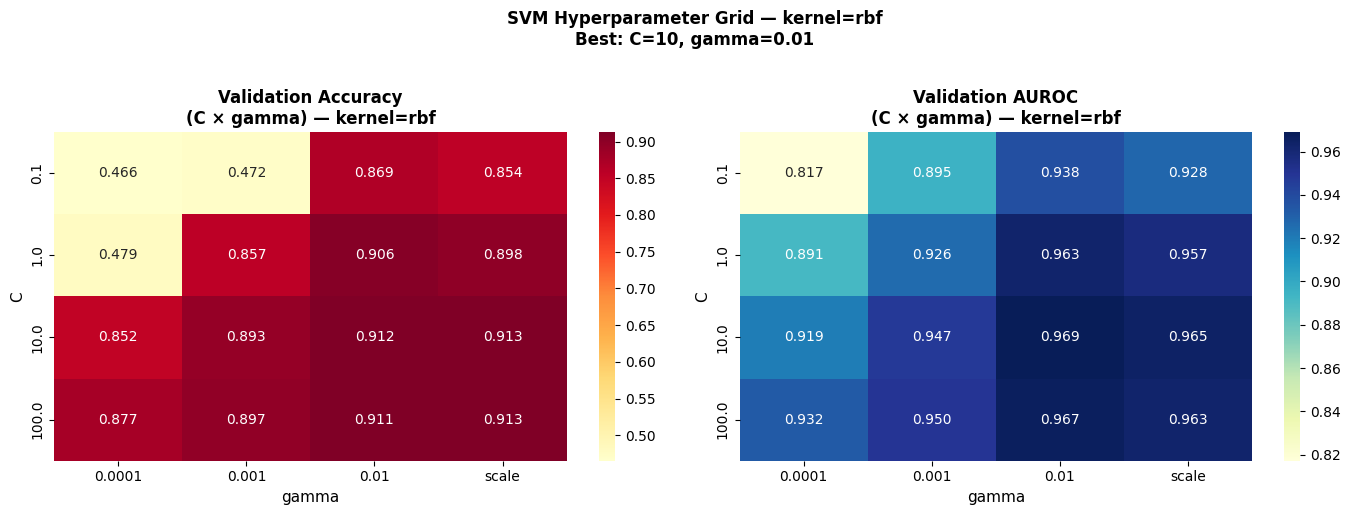


Best result per kernel:
kernel
rbf       0.9691
linear    0.9212


In [24]:
best_kernel = best_params['kernel']

subset = hp_results[hp_results['kernel'] == best_kernel].copy()

if best_kernel != 'linear' and len(subset['gamma'].unique()) > 1:
    pivot_acc   = subset.pivot_table(index='C', columns='gamma', values='val_accuracy', aggfunc='mean')
    pivot_auroc = subset.pivot_table(index='C', columns='gamma', values='val_auroc',   aggfunc='mean')

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, piv, title, cmap in zip(axes,
                                      [pivot_acc, pivot_auroc],
                                      ['Validation Accuracy', 'Validation AUROC'],
                                      ['YlOrRd', 'YlGnBu']):
        sns.heatmap(piv, annot=True, fmt='.3f', cmap=cmap, ax=ax)
        ax.set_title(f'{title}\n(C × gamma) — kernel={best_kernel}', fontweight='bold', fontsize=12)
        ax.set_xlabel('gamma', fontsize=11)
        ax.set_ylabel('C', fontsize=11)

    plt.suptitle(
        f'SVM Hyperparameter Grid — kernel={best_kernel}\n'
        f'Best: C={best_params["C"]}, gamma={best_params["gamma"]}',
        fontsize=12, fontweight='bold', y=1.02
    )
    plt.tight_layout()
    save_fig('svm_hp_heatmap.png')
    plt.show()
else:
    # Linear kernel: only C varies
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(subset['C'].astype(str), subset['val_auroc'], 'o-', color='purple', lw=2, ms=8)
    ax.set_xlabel('C (Regularisation)', fontsize=12)
    ax.set_ylabel('Validation AUROC', fontsize=12)
    ax.set_title(f'SVM Hyperparameter Search — kernel={best_kernel}', fontweight='bold')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    save_fig('svm_hp_curve.png')
    plt.show()

# Summary table: best per kernel
print("\nBest result per kernel:")
print(hp_results.groupby('kernel')['val_auroc'].max().sort_values(ascending=False).round(4).to_string())

## 7. Train Final SVM Model & Evaluate on External Test Set

In [25]:
print(f"Training final SVM on dev set ({len(y_dev):,} samples)...")
print(f"  kernel={best_params['kernel']}, C={best_params['C']}, "
      f"gamma={best_params['gamma']}, class_weight=balanced")

svm_model = SVC(
    kernel=best_params['kernel'],
    C=best_params['C'],
    gamma=best_params['gamma'],
    degree=best_params['degree'],
    class_weight='balanced',
    probability=True,
    random_state=42,
    max_iter=10000,
)
svm_model.fit(X_dev, y_dev)

y_pred_test = svm_model.predict(X_test)
y_prob_test = svm_model.predict_proba(X_test)[:, 1]
test_metrics = compute_metrics(y_test, y_pred_test, y_prob_test)

print_metrics(test_metrics,
    "External Test Set — SVM-1 (Avalon 1024 + MW + TPSA + cLogP + AromaticRings + BaN)")
print("\nRF-1 reference (paper target): Acc=0.917 | Prec=0.935 | Sens=0.884 | AUROC=0.973")

# Number of support vectors
print(f"\nSupport vectors: {svm_model.n_support_.sum():,} total "
      f"(Active={svm_model.n_support_[1]:,}, Inactive={svm_model.n_support_[0]:,})")
print(f"  ({100*svm_model.n_support_.sum()/len(y_dev):.1f}% of training data are support vectors)")

Training final SVM on dev set (12,094 samples)...
  kernel=rbf, C=10, gamma=0.01, class_weight=balanced

  External Test Set — SVM-1 (Avalon 1024 + MW + TPSA + cLogP + AromaticRings + BaN)
  Accuracy       : 0.9286
  Precision      : 0.9319
  Sensitivity    : 0.9134
  Specificity    : 0.9418
  F1             : 0.9225
  Kappa          : 0.8563
  MCC            : 0.8564
  AUROC          : 0.9768
  TP             : 1286
  TN             : 1522
  FP             : 94
  FN             : 122

RF-1 reference (paper target): Acc=0.917 | Prec=0.935 | Sens=0.884 | AUROC=0.973

Support vectors: 5,678 total (Active=2,457, Inactive=3,221)
  (46.9% of training data are support vectors)


### 7.1 ROC Curve

Saved to Drive: /content/drive/MyDrive/antimalarial_project/svm_roc_curve.png


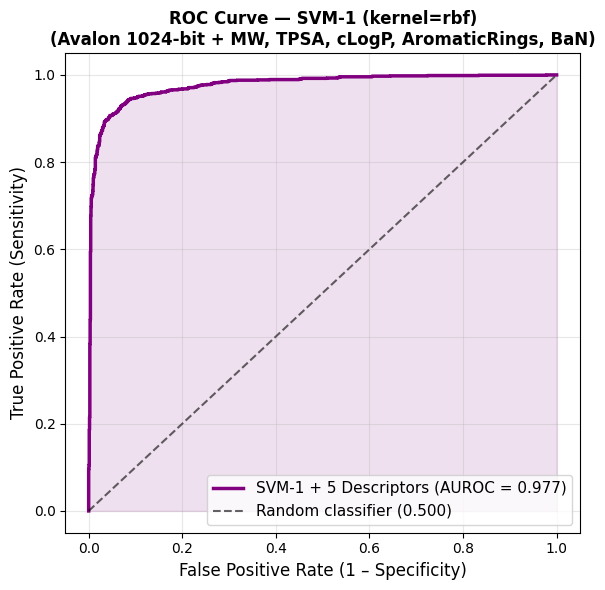

In [26]:
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
auroc = test_metrics['AUROC']

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color='purple', lw=2.5,
        label=f'SVM-1 + 5 Descriptors (AUROC = {auroc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.6, label='Random classifier (0.500)')
ax.fill_between(fpr, tpr, alpha=0.12, color='purple')
ax.set_xlabel('False Positive Rate (1 – Specificity)', fontsize=12)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
ax.set_title(
    f'ROC Curve — SVM-1 (kernel={best_params["kernel"]})\n'
    '(Avalon 1024-bit + MW, TPSA, cLogP, AromaticRings, BaN)',
    fontsize=12, fontweight='bold'
)
ax.legend(loc='lower right', fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('svm_roc_curve.png')
plt.show()

### 7.2 Confusion Matrix

Saved to Drive: /content/drive/MyDrive/antimalarial_project/svm_confusion_matrix.png


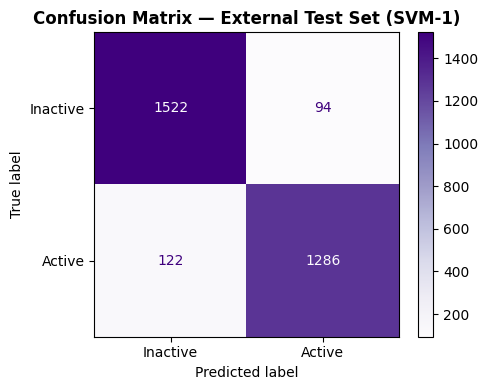

In [27]:
cm = confusion_matrix(y_test, y_pred_test)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Inactive', 'Active']).plot(
    ax=ax, colorbar=True, cmap='Purples')
ax.set_title('Confusion Matrix — External Test Set (SVM-1)', fontweight='bold')
plt.tight_layout()
save_fig('svm_confusion_matrix.png')
plt.show()

### 7.3 Decision Function Score Distribution

The SVM's raw decision function score shows how far each compound is from the decision boundary.
Positive score → predicted Active, Negative score → predicted Inactive.
A well-separated distribution (two distinct peaks) indicates a confident model.

Saved to Drive: /content/drive/MyDrive/antimalarial_project/svm_decision_scores.png


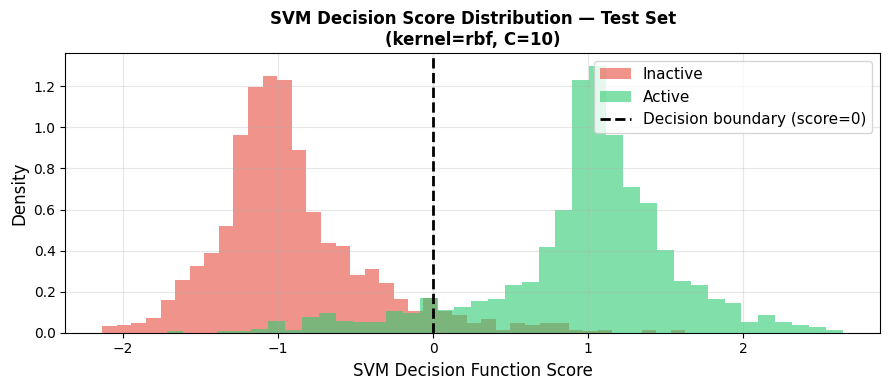

Mean decision score — Active  : 0.971
Mean decision score — Inactive: -0.912
Separation (difference of means): 1.884


In [28]:
decision_scores = svm_model.decision_function(X_test)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(decision_scores[y_test == 0], bins=40, alpha=0.6, color='#e74c3c',
        label='Inactive', density=True)
ax.hist(decision_scores[y_test == 1], bins=40, alpha=0.6, color='#2ecc71',
        label='Active', density=True)
ax.axvline(0, color='black', lw=2, ls='--', label='Decision boundary (score=0)')
ax.set_xlabel('SVM Decision Function Score', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.set_title(
    f'SVM Decision Score Distribution — Test Set\n'
    f'(kernel={best_params["kernel"]}, C={best_params["C"]})',
    fontweight='bold'
)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('svm_decision_scores.png')
plt.show()

# Separation summary
print(f"Mean decision score — Active  : {decision_scores[y_test==1].mean():.3f}")
print(f"Mean decision score — Inactive: {decision_scores[y_test==0].mean():.3f}")
print(f"Separation (difference of means): {decision_scores[y_test==1].mean() - decision_scores[y_test==0].mean():.3f}")

## 8. Model Validation

### 8.1 10-fold CV × 10 Repeats

In [ ]:
cv_records  = []
key_metrics = ['Accuracy','Precision','Sensitivity','Specificity','F1','Kappa','MCC','AUROC']

print("Running 10-fold CV x 10 repeats...")
print("(Note: SVM CV is slower than RF/XGBoost — this may take several minutes)")

for repeat in tqdm(range(10), desc="CV repeats"):
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=repeat)
    fold_m = []
    for tr_idx, v_idx in skf.split(X_dev, y_dev):
        svm_cv = SVC(
            kernel=best_params['kernel'],
            C=best_params['C'],
            gamma=best_params['gamma'],
            degree=best_params['degree'],
            class_weight='balanced',
            probability=True,
            random_state=42,
            max_iter=5000,
        )
        svm_cv.fit(X_dev[tr_idx], y_dev[tr_idx])
        m = compute_metrics(
            y_dev[v_idx],
            svm_cv.predict(X_dev[v_idx]),
            svm_cv.predict_proba(X_dev[v_idx])[:, 1]
        )
        fold_m.append(m)
    avg = {k: np.mean([fm[k] for fm in fold_m]) for k in key_metrics}
    avg['repeat'] = repeat + 1
    cv_records.append(avg)

cv_df      = pd.DataFrame(cv_records)
cv_summary = cv_df[key_metrics].agg(['mean','std'])
print("\n10-fold CV Results:")
print(cv_summary.round(4).to_string())

Running 10-fold CV x 10 repeats...
(Note: SVM CV is slower than RF/XGBoost — this may take several minutes)


CV repeats:   0%|          | 0/10 [00:00<?, ?it/s]

### 8.2 Y-Scrambling Validation

In [ ]:
rng = np.random.RandomState(42)
scrambled_accs = [accuracy_score(rng.permutation(y_test), y_pred_test)
                  for _ in tqdm(range(100), desc="Y-scrambling")]

print(f"\nY-Scrambling Validation:")
print(f"  Real model accuracy   : {test_metrics['Accuracy']:.4f}")
print(f"  Scrambled mean ± std  : {np.mean(scrambled_accs):.4f} ± {np.std(scrambled_accs):.4f}")
print(f"  Expected (random)     : ~0.500")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scrambled_accs, bins=25, color='mediumpurple', alpha=0.75, edgecolor='k',
        label=f'Y-scrambled (mean={np.mean(scrambled_accs):.3f})')
ax.axvline(test_metrics['Accuracy'], color='purple', lw=2.5, ls='--',
           label=f"Real model ({test_metrics['Accuracy']:.3f})")
ax.axvline(0.5, color='gray', lw=1.5, ls=':', label='Random (0.500)')
ax.set_xlabel('Accuracy'); ax.set_ylabel('Count')
ax.set_title('Y-Scrambling Validation (SVM-1)', fontweight='bold')
ax.legend(fontsize=11); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('svm_y_scrambling.png')
plt.show()

### 8.3 Effect of C (Regularisation) on Train vs Val Performance

This is the SVM equivalent of a learning curve — it shows how the regularisation
parameter C affects the trade-off between underfitting (too low C) and overfitting (too high C).

In [ ]:
C_sweep = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
train_aurocs, val_aurocs = [], []

for c in tqdm(C_sweep, desc="C sweep"):
    m = SVC(
        kernel=best_params['kernel'],
        C=c,
        gamma=best_params['gamma'],
        class_weight='balanced',
        probability=True,
        random_state=42,
        max_iter=5000,
    )
    m.fit(X_train, y_train)
    train_aurocs.append(roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]))
    val_aurocs.append(roc_auc_score(y_val,   m.predict_proba(X_val)[:,   1]))

fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogx(C_sweep, train_aurocs, 'b-o', ms=7, lw=2, label='Train AUROC')
ax.semilogx(C_sweep, val_aurocs,   'r-s', ms=7, lw=2, label='Val AUROC')
ax.axvline(best_params['C'], color='green', ls='--', lw=2,
           label=f'Best C={best_params["C"]}')
ax.set_xlabel('C (Regularisation — log scale)', fontsize=12)
ax.set_ylabel('AUROC', fontsize=12)
ax.set_title(
    f'Effect of C on Train vs Validation AUROC\n(kernel={best_params["kernel"]}, gamma={best_params["gamma"]})',
    fontsize=13, fontweight='bold'
)
ax.legend(fontsize=11); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('svm_c_sweep.png')
plt.show()

## 9. Applicability Domain (APD)

In [ ]:
n_samp   = min(2000, len(X_train_fp))
samp_idx = np.random.choice(len(X_train_fp), n_samp, replace=False)
X_samp   = X_train_fp[samp_idx]

print("Computing APD (Euclidean NN distances in Avalon space)...")
tr_d = cdist(X_samp, X_samp, metric='euclidean')
np.fill_diagonal(tr_d, np.inf)
train_nn_d = tr_d.min(axis=1)

APD_PERCENTILE = 99
apd_threshold  = np.percentile(train_nn_d, APD_PERCENTILE)

test_nn_d   = cdist(X_test_fp, X_train_fp, metric='euclidean').min(axis=1)
outside_apd = test_nn_d > apd_threshold

print(f"  APD threshold (P{APD_PERCENTILE}): {apd_threshold:.3f}")
print(f"  Outside APD: {outside_apd.sum()}/{len(X_test)} ({100*outside_apd.mean():.1f}%)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train_nn_d, bins=50, alpha=0.6, color='purple',    density=True, label='Training NN distances')
ax.hist(test_nn_d,  bins=50, alpha=0.6, color='mediumpurple', density=True, label='Test NN distances')
ax.axvline(apd_threshold, color='red', lw=2, ls='--',
           label=f'APD threshold = {apd_threshold:.2f}')
ax.set_xlabel('Euclidean Distance to Nearest Neighbour')
ax.set_ylabel('Density')
ax.set_title('Applicability Domain — Avalon 1024-bit Space (SVM-1)', fontweight='bold')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('svm_applicability_domain.png')
plt.show()

## 10. Feature Weights (Linear Kernel Only)

For the **linear SVM**, the model has explicit feature weights (`coef_`) that tell us
how much each feature pushes a compound toward Active (positive weight) or Inactive (negative weight).

For **RBF or Poly kernels**, there are no explicit weights — the model is non-linear and
feature importance must be approximated (e.g. via permutation importance).

In [ ]:
if best_params['kernel'] == 'linear':
    weights = svm_model.coef_[0]   # shape: (1029,)
    avalon_w = weights[:AVALON_NBITS]
    desc_w   = weights[AVALON_NBITS:]

    print("Linear SVM feature weights — 5 descriptors:")
    for name, val in zip(DESC_NAMES, desc_w):
        bar = '+' * int(abs(val)*100) if val > 0 else '-' * int(abs(val)*100)
        print(f"  {name:15s}: {val:+.5f}  {bar[:40]}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Descriptor weights
    ax = axes[0]
    colors = ['#2ecc71' if v > 0 else '#e74c3c' for v in desc_w]
    bars = ax.bar(DESC_NAMES, desc_w, color=colors, edgecolor='white', width=0.6)
    ax.axhline(0, color='black', lw=0.8)
    for b, v in zip(bars, desc_w):
        ax.text(b.get_x() + b.get_width()/2,
                v + (0.0002 if v >= 0 else -0.0004),
                f'{v:+.4f}', ha='center', fontsize=9)
    ax.set_ylabel('SVM Weight (positive = Active, negative = Inactive)')
    ax.set_title('Descriptor Weights — Linear SVM\n(green=Active-promoting, red=Inactive-promoting)',
                 fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

    # Top 30 Avalon bits by absolute weight
    ax2 = axes[1]
    top30 = np.argsort(np.abs(avalon_w))[::-1][:30]
    top30_colors = ['#2ecc71' if avalon_w[i] > 0 else '#e74c3c' for i in top30]
    ax2.bar(range(30), avalon_w[top30], color=top30_colors, edgecolor='white')
    ax2.axhline(0, color='black', lw=0.8)
    ax2.set_xticks(range(30))
    ax2.set_xticklabels([f'Bit {top30[i]}' for i in range(30)],
                        rotation=45, ha='right', fontsize=7)
    ax2.set_ylabel('SVM Weight')
    ax2.set_title('Top 30 Avalon Bits by |Weight|\n(green=Active, red=Inactive)', fontweight='bold')
    ax2.grid(axis='y', alpha=0.3)

    plt.suptitle('Feature Weights — SVM-1 (Linear Kernel)',
                 fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    save_fig('svm_feature_weights.png')
    plt.show()

else:
    # Non-linear kernel: use permutation importance
    print(f"Kernel={best_params['kernel']} — no explicit weights available.")
    print("Computing permutation importance on test set (slower but model-agnostic)...")

    from sklearn.inspection import permutation_importance
    result = permutation_importance(
        svm_model, X_test, y_test,
        n_repeats=10, random_state=42, scoring='roc_auc', n_jobs=-1
    )
    perm_imp = result.importances_mean

    desc_perm  = perm_imp[AVALON_NBITS:]
    avalon_perm = perm_imp[:AVALON_NBITS]

    print("\nPermutation importance — 5 descriptors (mean AUROC drop):")
    for name, val in zip(DESC_NAMES, desc_perm):
        print(f"  {name:15s}: {val:.6f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    bar_colors = ['#e74c3c' if v == desc_perm.max() else '#9b59b6' for v in desc_perm]
    bars = ax.bar(DESC_NAMES, desc_perm, color=bar_colors, edgecolor='white', width=0.6)
    for b, v in zip(bars, desc_perm):
        ax.text(b.get_x() + b.get_width()/2, v + 0.0001,
                f'{v:.5f}', ha='center', va='bottom', fontsize=9)
    ax.set_ylabel('Mean AUROC Drop (permutation importance)')
    ax.set_title('Permutation Importance — 5 Descriptors', fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

    ax2 = axes[1]
    top30 = np.argsort(avalon_perm)[::-1][:30]
    ax2.bar(range(30), avalon_perm[top30], color='#9b59b6', edgecolor='white')
    ax2.set_xticks(range(30))
    ax2.set_xticklabels([f'Bit {top30[i]}' for i in range(30)],
                        rotation=45, ha='right', fontsize=7)
    ax2.set_ylabel('Mean AUROC Drop')
    ax2.set_title('Top 30 Avalon Bits by Permutation Importance', fontweight='bold')
    ax2.grid(axis='y', alpha=0.3)

    plt.suptitle(f'Feature Importance — SVM-1 ({best_params["kernel"].upper()} Kernel, Permutation)',
                 fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    save_fig('svm_feature_importance.png')
    plt.show()

## 11. Virtual Screening — Predict New Compounds

In [ ]:
def screen_compounds(smiles_list, names=None):
    """
    Screen new SMILES strings using the trained SVM-1 model.
    Descriptors are calculated via OpenChemLib-JS.
    Returns: prediction, probability of activity, APD status, descriptors, decision score.
    """
    valid_entries, results = [], []
    for i, smi in enumerate(smiles_list):
        name = names[i] if names else f"Cpd_{i+1}"
        mol  = Chem.MolFromSmiles(str(smi))
        if mol is None:
            results.append({'Name': name, 'SMILES': smi,
                            'Prediction': 'Invalid SMILES', 'P(Active)': None,
                            'Decision_Score': None, 'Within_APD': None,
                            **{d: None for d in DESC_NAMES}})
        else:
            valid_entries.append((i, name, smi))

    if not valid_entries:
        return pd.DataFrame(results)

    valid_smiles = [e[2] for e in valid_entries]
    print(f"[OCL] Calculating descriptors for {len(valid_smiles)} molecules...")
    desc_map = run_ocl_descriptors(valid_smiles)

    for (i, name, smi) in valid_entries:
        if smi not in desc_map:
            results.append({'Name': name, 'SMILES': smi,
                            'Prediction': 'OCL error', 'P(Active)': None,
                            'Decision_Score': None, 'Within_APD': None,
                            **{d: None for d in DESC_NAMES}})
            continue
        try:
            mol     = Chem.MolFromSmiles(smi)
            desc    = desc_map[smi]
            fp      = calc_avalon_fp(mol, n_bits=AVALON_NBITS)
            desc_sc = scaler.transform(desc.reshape(1, -1))[0]
            feat    = np.hstack([fp, desc_sc]).reshape(1, -1).astype(np.float32)

            pred    = svm_model.predict(feat)[0]
            prob    = float(svm_model.predict_proba(feat)[0][1])
            dec_sc  = float(svm_model.decision_function(feat)[0])
            nn_dist = cdist(fp.reshape(1, -1), X_train_fp, metric='euclidean').min()
            in_apd  = bool(nn_dist <= apd_threshold)

            results.append({
                'Name':          name,
                'SMILES':        smi,
                'Prediction':    'Active' if pred == 1 else 'Inactive',
                'P(Active)':     round(prob, 4),
                'Decision_Score': round(dec_sc, 4),
                'Within_APD':    in_apd,
                'NN_Distance':   round(float(nn_dist), 3),
                **{d: round(float(desc[j]), 3) for j, d in enumerate(DESC_NAMES)}
            })
        except Exception as e:
            results.append({'Name': name, 'SMILES': smi,
                            'Prediction': f'Error: {e}', 'P(Active)': None,
                            'Decision_Score': None, 'Within_APD': None,
                            **{d: None for d in DESC_NAMES}})

    return pd.DataFrame(results)


# Example screening
example_smiles = [
    "CCc1cc2nc3cc(OC)ccc3c(=O)c2cc1OC",
    "ClC1=CC=C(C=C1)C(O)CN2CCN(CC2)C3=NC4=CC=CC=C4N3",
    "OC(=O)c1cc(=O)c2cc(OC(=O)C)ccc2o1",
]
example_names = ["Quinine", "Clotrimazole", "Aspirin-like"]

screen_df = screen_compounds(example_smiles, names=example_names)
print("\nVirtual Screening Results:")
print(screen_df[['Name', 'Prediction', 'P(Active)', 'Decision_Score',
                  'Within_APD', 'NN_Distance'] + DESC_NAMES].to_string(index=False))

## 12. Summary Dashboard

In [ ]:
fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.4)

# ROC
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(fpr, tpr, 'purple', lw=2.5, label=f'AUROC={auroc:.3f}')
ax1.plot([0,1],[0,1],'k--',lw=1,alpha=0.5)
ax1.fill_between(fpr,tpr,alpha=0.1,color='purple')
ax1.set_xlabel('FPR'); ax1.set_ylabel('TPR')
ax1.set_title('ROC Curve',fontweight='bold')
ax1.legend(fontsize=9); ax1.grid(alpha=0.3)

# Confusion matrix
ax2 = fig.add_subplot(gs[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=ax2,
            xticklabels=['Inactive','Active'], yticklabels=['Inactive','Active'])
ax2.set_title('Confusion Matrix',fontweight='bold')
ax2.set_xlabel('Predicted'); ax2.set_ylabel('Actual')

# Metrics bar
ax3 = fig.add_subplot(gs[0, 2])
mk = ['Accuracy','Precision','Sensitivity','Specificity','F1','MCC','AUROC']
mv = [test_metrics[k] for k in mk]
bars3 = ax3.barh(mk, mv, color='#8e44ad', edgecolor='white')
ax3.set_xlim([0,1.15])
for b,v in zip(bars3,mv):
    ax3.text(v+0.01,b.get_y()+b.get_height()/2,f'{v:.3f}',va='center',fontsize=9)
ax3.set_title('Test Metrics',fontweight='bold'); ax3.grid(axis='x',alpha=0.3)

# CV boxplots
ax4 = fig.add_subplot(gs[1, :])
cv_df[['Accuracy','Precision','Sensitivity','Specificity','F1','Kappa','MCC','AUROC']].boxplot(
    ax=ax4, patch_artist=True,
    boxprops=dict(facecolor='thistle', color='purple'),
    medianprops=dict(color='red', lw=2))
ax4.set_title('10-fold CV x 10 Repeats',fontweight='bold',fontsize=12)
ax4.set_ylabel('Score'); ax4.grid(alpha=0.3); ax4.set_ylim([0.7,1.05])

# Decision score distribution
ax5 = fig.add_subplot(gs[2, 0])
ax5.hist(decision_scores[y_test==0], bins=30, alpha=0.6, color='#e74c3c',
         density=True, label='Inactive')
ax5.hist(decision_scores[y_test==1], bins=30, alpha=0.6, color='#2ecc71',
         density=True, label='Active')
ax5.axvline(0, color='black', lw=1.5, ls='--')
ax5.set_title('Decision Scores',fontweight='bold',fontsize=11)
ax5.set_xlabel('Score'); ax5.legend(fontsize=9); ax5.grid(alpha=0.3)

# Y-scrambling
ax6 = fig.add_subplot(gs[2, 1])
ax6.hist(scrambled_accs, bins=20, color='mediumpurple', alpha=0.75, edgecolor='k')
ax6.axvline(test_metrics['Accuracy'], color='purple', lw=2, ls='--',
            label=f"Model ({test_metrics['Accuracy']:.3f})")
ax6.axvline(0.5, color='gray', lw=1.5, ls=':', label='Random')
ax6.set_title('Y-Scrambling',fontweight='bold',fontsize=11)
ax6.set_xlabel('Accuracy'); ax6.legend(fontsize=9); ax6.grid(alpha=0.3)

# APD
ax7 = fig.add_subplot(gs[2, 2])
ax7.hist(train_nn_d, bins=40, alpha=0.6, color='purple',       density=True, label='Train NN')
ax7.hist(test_nn_d,  bins=40, alpha=0.6, color='mediumpurple', density=True, label='Test NN')
ax7.axvline(apd_threshold, color='red', lw=2, ls='--', label=f'APD={apd_threshold:.1f}')
ax7.set_title('Applicability Domain',fontweight='bold',fontsize=11)
ax7.set_xlabel('NN Distance'); ax7.legend(fontsize=9); ax7.grid(alpha=0.3)

plt.suptitle(
    f'SVM-1 Summary Dashboard — Antimalarial Classifier\n'
    f'(Avalon {AVALON_NBITS}-bit + {len(DESC_NAMES)} Descriptors | '
    f'kernel={best_params["kernel"]}, C={best_params["C"]}, gamma={best_params["gamma"]})',
    fontsize=13, fontweight='bold', y=1.01
)
save_fig('svm_summary_dashboard.png')
plt.show()

## 13. Save Model

In [ ]:
model_bundle = {
    'model':         svm_model,
    'scaler':        scaler,
    'fingerprint':   'avalon',
    'n_bits':        AVALON_NBITS,
    'descriptors':   DESC_NAMES,
    'n_features':    X_train.shape[1],
    'kernel':        best_params['kernel'],
    'C':             best_params['C'],
    'gamma':         best_params['gamma'],
    'degree':        best_params['degree'],
    'apd_threshold': apd_threshold,
    'ban_source':    'OpenChemLib-JS (pKa-based port of AtomFunctionAnalyzer)',
    'test_metrics':  test_metrics,
    'n_support_vectors': int(svm_model.n_support_.sum()),
}

# Save locally
with open('svm1_antimalarial_model.pkl', 'wb') as f:
    pickle.dump(model_bundle, f)
print("Model saved to svm1_antimalarial_model.pkl")

# Save to Drive
model_path = PROJECT_DIR + 'svm1_antimalarial_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(model_bundle, f)
print(f"Model saved to Drive: {model_path}")

print(f"\nModel Summary:")
print(f"  Features          : Avalon {AVALON_NBITS} bits + {', '.join(DESC_NAMES)} = {X_train.shape[1]} total")
print(f"  Kernel            : {best_params['kernel']}")
print(f"  C / gamma         : {best_params['C']} / {best_params['gamma']}")
print(f"  Support vectors   : {svm_model.n_support_.sum():,}")
print(f"  BaN source        : {model_bundle['ban_source']}")
for k in ['Accuracy','Precision','Sensitivity','Specificity','F1','Kappa','MCC','AUROC']:
    print(f"  {k:15s}: {test_metrics[k]:.4f}")

---
## Notes

### Feature Vector Layout
```
Index  0 – 1023 : Avalon fingerprint bits (binary)
Index 1024      : MW            (standardised, OpenChemLib)
Index 1025      : TPSA          (standardised, OpenChemLib)
Index 1026      : cLogP         (standardised, OpenChemLib)
Index 1027      : AromaticRings (standardised, OpenChemLib)
Index 1028      : BaN           (standardised, OpenChemLib pKa-based)
```

### Model Comparison
| Aspect | RF-1 | XGB-1 | SVM-1 |
|--------|------|-------|-------|
| Algorithm | Bagging | Boosting | Maximum Margin Hyperplane |
| Key params | n_trees, max_depth | n_estimators, lr, max_depth | C, gamma, kernel |
| Handles imbalance | class_weight | scale_pos_weight | class_weight='balanced' |
| Feature scaling needed | No | No | **Yes — critical** |
| Probabilities | Native | Native | Via Platt scaling |
| Feature importance | Native (MDI) | Native (gain) | Linear: weights; RBF: permutation |
| Speed on large data | Fast | Moderate | Slow (O(n²–n³)) |
| Works well when | Noisy data, many features | Complex patterns, structured data | Clear margin between classes |

### SVM-specific Considerations
- **Scaling is non-negotiable:** SVM computes distances in feature space — unscaled features will dominate.
- **`class_weight='balanced'`:** Automatically adjusts C inversely proportional to class frequency.
- **`probability=True`:** Adds Platt scaling (an extra logistic regression layer) to produce probabilities. Slightly slower to train but needed for AUROC.
- **Support vectors:** The model is defined only by the training points closest to the boundary (support vectors). The rest of the training data can be discarded after training.
- **Kernel choice:** RBF is a good default. Linear is faster for high-dimensional data (like 1024-bit fingerprints). Poly is rarely the best for molecular data.

*Paper: Kore M et al. BMC Chemistry 19, 28 (2025). https://doi.org/10.1186/s13065-025-01395-4*